<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Modelo de lenguaje con tokenización por caracteres

### Consigna
- Seleccionar un corpus de texto sobre el cual entrenar el modelo de lenguaje.
- Realizar el pre-procesamiento adecuado para tokenizar el corpus, estructurar el dataset y separar entre datos de entrenamiento y validación.
- Proponer arquitecturas de redes neuronales basadas en unidades recurrentes para implementar un modelo de lenguaje.
- Con el o los modelos que consideren adecuados, generar nuevas secuencias a partir de secuencias de contexto con las estrategias de greedy search y beam search determístico y estocástico. En este último caso observar el efecto de la temperatura en la generación de secuencias.


### Sugerencias
- Durante el entrenamiento, guiarse por el descenso de la perplejidad en los datos de validación para finalizar el entrenamiento. Para ello se provee un callback.
- Explorar utilizar SimpleRNN (celda de Elman), LSTM y GRU.
- rmsprop es el optimizador recomendado para la buena convergencia. No obstante se pueden explorar otros.


In [2]:
import random
import io
import re
import time
import pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from keras.layers import Input, CategoryEncoding, SimpleRNN, LSTM, GRU, Dense
from keras.models import Sequential

# semillas para reproducibilidad
random.seed(42)
np.random.seed(42)
keras.utils.set_random_seed(42)

### Datos
Utilizaremos como corpus los cuentos de **Julio Cortázar** recopilados por Karen Palacio en su repositorio
https://github.com/karen-pal/borges/tree/master/datasets/datasets_csv (archivo `cortazar_full_texts.csv`).

In [3]:
# Descargar el dataset
import os
import urllib.request

url = 'https://raw.githubusercontent.com/karen-pal/borges/master/datasets/datasets_csv/cortazar_full_texts.csv'
if os.access('cortazar_full_texts.csv', os.F_OK) is False:
    urllib.request.urlretrieve(url, 'cortazar_full_texts.csv')
else:
    print("El dataset ya se encuentra descargado")

El dataset ya se encuentra descargado


In [4]:
df = pd.read_csv('cortazar_full_texts.csv')
print("Cantidad de textos:", df.shape[0])
df.head()

Cantidad de textos: 55


,link,text_metadata,text
0,https://ciudadseva.com/texto/almuerzos/,"{'title': 'Almuerzos', 'metadata': '[Minicuent...",En el restaurante de los cronopios pasan estas...
1,https://ciudadseva.com/texto/amor-77/,"{'title': 'Amor 77', 'metadata': '[Minicuento ...","Y después de hacer todo lo que hacen, se levan..."
2,https://ciudadseva.com/texto/axolotl/,"{'title': 'Axolotl', 'metadata': '[Cuento - Te...",Hubo un tiempo en que yo pensaba mucho en los ...
3,https://ciudadseva.com/texto/bestiario/,"{'title': 'Bestiario', 'metadata': '[Cuento - ...",Entre la última cucharada de arroz con leche —...
4,https://ciudadseva.com/texto/carta-a-una-senor...,"{'title': 'Carta a una señorita en París', 'me...","Andrée, yo no quería venirme a vivir a su depa..."


Unimos todos los cuentos en un único texto, pasamos a minúscula y colapsamos saltos de línea / espacios múltiples en un solo espacio

In [ ]:
article_text = ' '.join(df.text.dropna().to_list()).lower()
article_text = re.sub(r'\s+', ' ', article_text)

# normalizamos variantes tipográficas de comillas y guiones
article_text = article_text.translate(str.maketrans({'’': "'", '‘': "'", '“': '"', '”': '"', '«': '"', '»': '"', '–': '—'}))

# eliminamos caracteres muy poco frecuentes (aparecen menos de 5 veces en todo el corpus)
char_counts = Counter(article_text)
rare_chars = {ch for ch, cnt in char_counts.items() if cnt < 5}
article_text = ''.join(ch for ch in article_text if ch not in rare_chars)

print(f"Caracteres eliminados por poco frecuentes: {sorted(rare_chars)}")
print(f"Longitud del corpus: {len(article_text)} caracteres")

Caracteres eliminados por poco frecuentes: ['°', '²', '³', '¹', 'º', 'â', 'ë', 'ô', 'ù']
Longitud del corpus: 751335 caracteres


In [ ]:
article_text[:1000]

'en el restaurante de los cronopios pasan estas cosas, a saber, que un fama pide con gran concentración un bife con papas fritas, y se queda deunapieza cuando el cronopio camarero le pregunta cuántas papas fritas quiere. —¿cómo cuántas? —vocifera el fama—. ¡usted me trae papas fritas y se acabó, qué joder! —es que aquí las servimos de a siete, treinta y dos, o noventa y ocho —explica el cronopio. el fama medita un momento, y el resultado de su meditación consiste en decirle al cronopio: —vea, mi amigo, váyase al carajo. para inmensa sorpresa del fama, el cronopio obedece instantáneamente, es decir que desaparece como si se lo hubiera bebido el viento. por supuesto el fama no llegará a saber jamás dónde queda el tal carajo, y el cronopio probablemente tampoco, pero en todo caso el almuerzo dista de ser un éxito. fin papeles inesperados, 2009 y después de hacer todo lo que hacen, se levantan, se bañan, se entalcan, se perfuman, se visten y, así progresivamente, van volviendo a ser lo que

### Elegir el tamaño del contexto

En este caso, como el modelo de lenguaje es por caracteres, todo un gran corpus
de texto puede ser considerado un documento en sí mismo y el tamaño de contexto
puede ser elegido con más libertad en comparación a un modelo de lenguaje tokenizado por palabras y dividido en documentos más acotados.

Elegimos 100 caracteres: equivale a unas 15-20 palabras en español, suficiente para capturar la palabra en curso y parte de la oración, manteniendo acotado el costo de la retropropagación en el tiempo (BPTT).

In [7]:
# seleccionamos el tamaño de contexto
max_context_size = 100

In [8]:
# Usaremos las utilidades de procesamiento de textos y secuencias de Keras
from tensorflow.keras.utils import pad_sequences # se utilizará para padding

In [9]:
# en este caso el vocabulario es el conjunto único de caracteres que existe en todo el texto.
# Lo ordenamos para que el mapeo sea reproducible entre ejecuciones (el orden de un `set` no lo es)
chars_vocab = sorted(set(article_text))

In [10]:
# la longitud de vocabulario de caracteres es:
len(chars_vocab)

61

In [ ]:
# Construimos los dicionarios que asignan índices a caracteres y viceversa.
# El diccionario `char2idx` servirá como tokenizador.
char2idx = {k: v+1 for v,k in enumerate(chars_vocab)}
idx2char = {v: k for k,v in char2idx.items()}

# tamaño del vocabulario incluyendo el token de padding
vocab_size = len(chars_vocab) + 1
vocab_size

62

###  Tokenizar

In [13]:
# tokenizamos el texto completo
tokenized_text = [char2idx[ch] for ch in article_text]

In [14]:
tokenized_text[:50]

[28,
 37,
 1,
 28,
 35,
 1,
 41,
 28,
 42,
 43,
 24,
 44,
 41,
 24,
 37,
 43,
 28,
 1,
 27,
 28,
 1,
 35,
 38,
 42,
 1,
 26,
 41,
 38,
 37,
 38,
 39,
 32,
 38,
 42,
 1,
 39,
 24,
 42,
 24,
 37,
 1,
 28,
 42,
 43,
 24,
 42,
 1,
 26,
 38,
 42]

### Organizando y estructurando el dataset

In [15]:
# separaremos el dataset entre entrenamiento y validación.
# `p_val` será la proporción del corpus que se reservará para validación
# `num_val` es la cantidad de secuencias de tamaño `max_context_size` que se usará en validación
p_val = 0.1
num_val = int(np.ceil(len(tokenized_text)*p_val/max_context_size))

In [16]:
# separamos la porción de texto utilizada en entrenamiento de la de validación.
# Al tomar el final del corpus, los textos de validación no se solapan con los de entrenamiento.
train_text = tokenized_text[:-num_val*max_context_size]
val_text = tokenized_text[-num_val*max_context_size:]

In [ ]:
# secuencias de validación contiguas y no solapadas de tamaño `max_context_size`
tokenized_sentences_val = [val_text[init*max_context_size:(init+1)*max_context_size] for init in range(num_val)]
len(tokenized_sentences_val)

752

In [18]:
# Armamos ventanas de tamaño `max_context_size+1` sobre el texto de entrenamiento.
# Con `stride`=1 tendríamos ~675k ventanas casi idénticas entre sí; con un salto de 5 caracteres
# reducimos el costo de cada epoch (entrenamos en CPU) sin perder cobertura del corpus.
stride = 5
windows = np.array([train_text[init:init+max_context_size+1]
                    for init in range(0, len(train_text)-max_context_size, stride)], dtype='int32')

X = windows[:, :-1]
y = windows[:, 1:]

Nótese que estamos estructurando el problema de aprendizaje como *many-to-many*:

Entrada: secuencia de tokens [$x_0$, $x_1$, ..., $x_N$]

Target: secuencia de tokens [$x_1$, $x_2$, ..., $x_{N+1}$]

De manera que la red tiene que aprender que su salida deben ser los tokens desplazados en una posición y un nuevo token predicho (el N+1).

La ventaja de estructurar el aprendizaje de esta manera es que para cada token de target se propaga una señal de gradiente por el grafo de cómputo recurrente, que es mejor que estructurar el problema como *many-to-one* en donde sólo una señal de gradiente se propaga.

In [19]:
X.shape, y.shape

((135207, 100), (135207, 100))

In [20]:
X[0,:10]

array([28, 37,  1, 28, 35,  1, 41, 28, 42, 43], dtype=int32)

In [21]:
y[0,:10]

array([37,  1, 28, 35,  1, 41, 28, 42, 43, 24], dtype=int32)

# Definiendo el modelo

El modelo consume los índices de los tokens y los transforma en vectores OHE (en este caso no entrenamos una capa de embedding para caracteres) mediante la capa `CategoryEncoding`, que aplicada sobre una secuencia de índices devuelve un vector OHE por cada paso temporal.

Se comparan las tres celdas recurrentes vistas en clase, con la misma cantidad de unidades:
- **SimpleRNN (Elman)**: $h_t = \tanh(W_{hh} h_{t-1} + W_{hx} x_t + b)$. Es la más liviana pero sufre de *vanishing gradients*.
- **LSTM**: agrega una memoria de largo plazo $c_t$ controlada por las compuertas de entrada, olvido y salida.
- **GRU**: versión reducida de la LSTM, con compuertas de *reset* y *update*.

In [22]:
def build_model(cell, units=200):
    """Modelo de lenguaje many-to-many: OHE -> capa recurrente -> softmax sobre el vocabulario"""
    model = Sequential(name=cell.__name__)
    model.add(Input(shape=(None,), dtype='int32'))
    model.add(CategoryEncoding(num_tokens=vocab_size, output_mode="one_hot"))
    model.add(cell(units, return_sequences=True, dropout=0.1, recurrent_dropout=0.1))
    model.add(Dense(vocab_size, activation='softmax'))
    model.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop')
    return model

build_model(LSTM).summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ category_encoding               │ (None, None, 62)       │             0 │
│ (CategoryEncoding)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, None, 200)      │       210,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 62)       │        12,462 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,862 (870.55 KB)

 Trainable params: 222,862 (870.55 KB)

 Non-trainable params: 0 (0.00 B)

### Callback de perplejidad
Dado que por el momento no hay implementaciones adecuadas de la perplejidad que puedan operar en tiempo de entrenamiento, armaremos un Callback *ad-hoc* que la calcule en cada epoch.

**Nota**: un Callback es una rutina gatillada por algún evento, son muy útiles para relevar datos en diferentes momentos del desarrollo del modelo. En este caso queremos hacer un cálculo cada vez que termina una epoch de entrenamiento.

Como el modelo es *many-to-many* y la red recurrente es causal (la salida en el paso $t$ sólo depende de $x_0..x_t$), con **una única pasada** por cada secuencia de validación obtenemos $P(x_{t+1} \mid x_0, \dots, x_t)$ para todos los $t$. Esto es equivalente a armar todas las sub-secuencias con padding, pero evita predecir ~100 veces cada secuencia (lo cual requería varios GB de memoria).

In [23]:
class PplCallback(keras.callbacks.Callback):

    """
    Este callback es una solución ad-hoc para calcular al final de cada epoch de
    entrenamiento la métrica de Perplejidad sobre un conjunto de datos de validación.
    La perplejidad es una métrica cuantitativa para evaluar la calidad de la generación de secuencias.
    Además implementa la finalización del entrenamiento (Early Stopping)
    si la perplejidad no mejora después de `patience` epochs, y guarda el mejor modelo en `save_path`.
    """

    def __init__(self, val_data, save_path, patience=5):
      super().__init__()
      # El callback lo inicializamos con secuencias de validación sobre las cuales
      # mediremos la perplejidad
      val_data = np.array(val_data, dtype='int32')
      # entrada: la secuencia sin su último token; target: la secuencia desplazada
      self.inputs = val_data[:, :-1]
      self.targets = val_data[:, 1:]

      self.save_path = save_path
      self.history_ppl = []
      self.min_score = np.inf
      self.patience_counter = 0
      self.patience = patience


    def on_epoch_end(self, epoch, logs=None):

        predictions = self.model.predict(self.inputs, batch_size=512, verbose=0)

        # probabilidad asignada a cada token target
        probs = np.take_along_axis(predictions, self.targets[..., None], axis=-1)[..., 0]

        # perplejidad de cada secuencia (por medio de logaritmos) y promedio entre secuencias
        scores = np.exp(-np.mean(np.log(probs + 1e-10), axis=1))
        current_score = np.mean(scores)
        self.history_ppl.append(current_score)
        print(f'\n mean perplexity: {current_score} \n')

        # chequeamos si tenemos que detener el entrenamiento
        if current_score < self.min_score:
          self.min_score = current_score
          self.model.save(self.save_path)
          print("Saved new model!")
          self.patience_counter = 0
        else:
          self.patience_counter += 1
          if self.patience_counter == self.patience:
            print("Stopping training...")
            self.model.stop_training = True

### Entrenamiento
Entrenamos las tres arquitecturas con `rmsprop` (optimizador recomendado), guiándonos por la perplejidad en validación para detener el entrenamiento (paciencia de 3 epochs). Como referencia, un modelo que asigna probabilidad uniforme a todos los caracteres tendría perplejidad igual al tamaño del vocabulario.

In [24]:
print(f"Perplejidad de un modelo equiprobable: {vocab_size}")

results = {}
for cell in [SimpleRNN, LSTM, GRU]:
    name = cell.__name__
    print(f"\n========== {name} ==========")
    model = build_model(cell)
    ppl_cb = PplCallback(tokenized_sentences_val, save_path=f"model_{name.lower()}.keras", patience=3)

    start = time.time()
    # El batch_size lo podemos seleccionar a mano: en general, lo mejor es escoger el batch
    # más grande posible que minimice el tiempo de cada época.
    model.fit(X, y, epochs=15, callbacks=[ppl_cb], batch_size=256, verbose=2)
    elapsed = time.time() - start

    results[name] = {
        'history_ppl': ppl_cb.history_ppl,
        'best_ppl': ppl_cb.min_score,
        'epochs': len(ppl_cb.history_ppl),
        'min_por_epoch': elapsed / 60 / len(ppl_cb.history_ppl),
        'parametros': model.count_params(),
    }

Perplejidad de un modelo equiprobable: 62

========== SimpleRNN ==========
Epoch 1/15

 mean perplexity: 8.237716674804688 

Saved new model!
529/529 - 43s - 80ms/step - loss: 2.3675
Epoch 2/15

 mean perplexity: 7.149724960327148 

Saved new model!
529/529 - 43s - 82ms/step - loss: 2.0871
Epoch 3/15

 mean perplexity: 6.559078216552734 

Saved new model!
529/529 - 42s - 80ms/step - loss: 1.9871
Epoch 4/15

 mean perplexity: 6.226108074188232 

Saved new model!
529/529 - 41s - 78ms/step - loss: 1.9241
Epoch 5/15

 mean perplexity: 6.01556921005249 

Saved new model!
529/529 - 41s - 78ms/step - loss: 1.8818
Epoch 6/15

 mean perplexity: 5.866097927093506 

Saved new model!
529/529 - 48s - 91ms/step - loss: 1.8511
Epoch 7/15

 mean perplexity: 5.787288665771484 

Saved new model!
529/529 - 53s - 100ms/step - loss: 1.8283
Epoch 8/15

 mean perplexity: 5.669224739074707 

Saved new model!
529/529 - 54s - 102ms/step - loss: 1.8113
Epoch 9/15

 mean perplexity: 5.622980117797852 

Saved new 

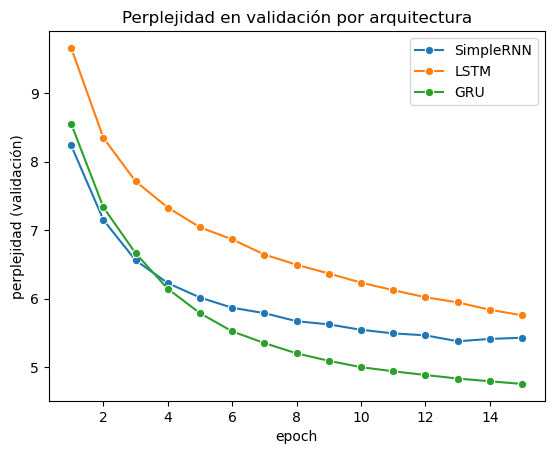

In [25]:
# Curvas de perplejidad en validación
for name, res in results.items():
    epoch_count = range(1, len(res['history_ppl']) + 1)
    sns.lineplot(x=epoch_count, y=res['history_ppl'], label=name, marker='o')
plt.xlabel('epoch')
plt.ylabel('perplejidad (validación)')
plt.title('Perplejidad en validación por arquitectura')
plt.show()

In [26]:
summary = pd.DataFrame(results).T.drop(columns='history_ppl')
summary

,best_ppl,epochs,min_por_epoch,parametros
SimpleRNN,5.376721,15,0.834282,65062
LSTM,5.755897,15,3.300558,222862
GRU,4.752995,15,2.76874,170862


Observamos que el mejor modelo es GRU por tener menor la perplejidad

In [27]:
# Cargamos el mejor modelo guardado del entrenamiento para hacer inferencia
best_name = summary['best_ppl'].astype(float).idxmin()
print(f"Mejor modelo: {best_name}")
model = keras.models.load_model(f'model_{best_name.lower()}.keras')

Mejor modelo: GRU


### Predicción del próximo caracter

In [36]:
# Se puede usar gradio para probar el modelo
# Gradio es una herramienta muy útil para crear interfaces para ensayar modelos
# https://gradio.app/

!pip install -q gradio

In [39]:
def model_response(human_text):

    # Encodeamos
    encoded = [char2idx[ch] for ch in human_text.lower() ]
    # Si tienen distinto largo
    encoded = pad_sequences([encoded], maxlen=max_context_size, padding='pre')

    # Predicción softmax
    y_hat = np.argmax(model.predict(encoded, verbose=0)[0,-1,:])

    # Debemos buscar en el vocabulario el caracter
    # que corresopnde al indice (y_hat) predicho por le modelo
    out_word = idx2char.get(y_hat, '')

    # Agrego la palabra a la frase predicha
    return human_text + out_word

for text in ['los cronopio', 'la cas', 'me acuerdo de aquella noch']:
    print(repr(model_response(text)))

'los cronopios'
'la casa'
'me acuerdo de aquella noche'


In [38]:
import gradio as gr
iface = gr.Interface(fn=model_response, inputs=["textbox"], outputs="text")
iface.launch(debug=True)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Keyboard interruption in main thread... closing server.


### Generación de secuencias

#### Greedy search
En cada paso se elige el caracter de mayor probabilidad.

In [29]:
def generate_seq(model, seed_text, max_length, n_words):
    """
        Exec model sequence prediction

        Args:
            model (keras): modelo entrenado
            seed_text (string): texto de entrada (input_seq)
            max_length (int): máxima longitud de la sequencia de entrada
            n_words (int): números de caracteres a agregar a la sequencia de entrada
        returns:
            output_text (string): sentencia con las "n_words" agregadas
    """
    output_text = seed_text
    # generate a fixed number of words
    for _ in range(n_words):
        # Encodeamos
        encoded = [char2idx[ch] for ch in output_text.lower() ]
        # Si tienen distinto largo
        encoded = pad_sequences([encoded], maxlen=max_length, padding='pre')

        # Predicción softmax
        y_hat = np.argmax(model.predict(encoded,verbose=0)[0,-1,:])
        # Vamos concatenando las predicciones
        out_word = idx2char.get(y_hat, '')

        # Agrego las palabras a la frase predicha
        output_text += out_word
    return output_text

In [30]:
seeds = ['los cronopios', 'un fama', 'la casa estaba', 'cuando llegamos a la ciudad']

for seed in seeds:
    print(repr(generate_seq(model, seed, max_length=max_context_size, n_words=80)))

'los cronopios y el pasajero de la cara de la cara de la cara de la cara de la cara de la cara'
'un fama y al paracio de la cara de la cara de la cara de la cara de la cara de la cara '
'la casa estaba con un poco a la cara de la cara de la cara de la cara de la cara de la cara de'
'cuando llegamos a la ciudad de la cara de la cara de la cara de la cara de la cara de la cara de la cara de'


###  Beam search y muestreo aleatorio

In [31]:
# funcionalidades para hacer encoding y decoding

def encode(text,max_length=max_context_size):

    encoded = [char2idx[ch] for ch in text.lower()]
    encoded = pad_sequences([encoded], maxlen=max_length, padding='pre')

    return encoded

def decode(seq):
    # se ignora el token 0 (padding)
    return ''.join([idx2char[ch] for ch in seq if ch != 0])

In [32]:
from scipy.special import softmax

# función que selecciona candidatos para el beam search
def select_candidates(pred,num_beams,vocab_size,history_probs,history_tokens,temp,mode):

  # colectar todas las probabilidades para la siguiente búsqueda
  pred_large = []

  for idx,pp in enumerate(pred):
    pred_large.extend(np.log(pp+1E-10)+history_probs[idx])

  pred_large = np.array(pred_large)

  # criterio de selección
  if mode == 'det':
    idx_select = np.argsort(pred_large)[::-1][:num_beams] # beam search determinista
  elif mode == 'sto':
    idx_select = np.random.choice(np.arange(pred_large.shape[0]), num_beams, p=softmax(pred_large/temp)) # beam search con muestreo aleatorio
  else:
    raise ValueError(f'Wrong selection mode. {mode} was given. det and sto are supported.')

  # traducir a índices de token en el vocabulario
  new_history_tokens = np.concatenate((np.array(history_tokens)[idx_select//vocab_size],
                        np.array([idx_select%vocab_size]).T),
                      axis=1)

  # devolver el producto de las probabilidades (log) y la secuencia de tokens seleccionados
  return pred_large[idx_select.astype(int)], new_history_tokens.astype(int)


def beam_search(model,num_beams,num_words,input,temp=1,mode='det'):

    # first iteration

    # encode
    encoded = encode(input)

    # first prediction
    y_hat = model.predict(encoded,verbose=0)[0,-1,:]

    # get vocabulary size
    vocab_size = y_hat.shape[0]

    # initialize history
    history_probs = [0]*num_beams
    history_tokens = [encoded[0]]*num_beams

    # select num_beams candidates
    history_probs, history_tokens = select_candidates([y_hat],
                                        num_beams,
                                        vocab_size,
                                        history_probs,
                                        history_tokens,
                                        temp,
                                        mode)

    # beam search loop
    for i in range(num_words-1):

      preds = []

      for hist in history_tokens:

        # actualizar secuencia de tokens
        input_update = np.array([hist[i+1:]]).copy()

        # predicción
        y_hat = model.predict(input_update,verbose=0)[0,-1,:]

        preds.append(y_hat)

      history_probs, history_tokens = select_candidates(preds,
                                                        num_beams,
                                                        vocab_size,
                                                        history_probs,
                                                        history_tokens,
                                                        temp,
                                                        mode)

    return history_tokens[:,-(len(input)+num_words):], history_probs

#### Beam search determinístico
En cada paso se mantienen los `num_beams` caminos de mayor probabilidad acumulada (suma de log-probabilidades).

In [33]:
seed = 'los cronopios'

for num_beams in [5, 10]:
    salidas, log_probs = beam_search(model, num_beams=num_beams, num_words=60, input=seed, mode='det')
    print(f"\n--- num_beams = {num_beams} ---")
    for out, lp in list(zip(salidas, log_probs))[:5]:
        print(f"{lp:8.2f} | {decode(out)!r}")


--- num_beams = 5 ---
  -38.47 | 'los cronopios en la carta de la cara de la cara de la cara de la cara de '
  -38.71 | 'los cronopios en la cara de la cara de la cara de la cara de la cara de l'
  -39.02 | 'los cronopios en la casa de la cara de la cara de la cara de la cara de l'
  -39.10 | 'los cronopios en la cara de la cara de la cara de la cara de la casa de l'
  -39.38 | 'los cronopios en la carta de la cara de la cara de la cara de la cara en '

--- num_beams = 10 ---
  -38.47 | 'los cronopios en la carta de la cara de la cara de la cara de la cara de '
  -38.71 | 'los cronopios en la cara de la cara de la cara de la cara de la cara de l'
  -39.02 | 'los cronopios en la casa de la cara de la cara de la cara de la cara de l'
  -39.06 | 'los cronopios en la cara en la cara de la cara de la cara de la cara de l'
  -39.08 | 'los cronopios en la cara de la cara de la cara en la cara de la cara de l'


#### Beam search estocástico y efecto de la temperatura
Los candidatos se muestrean de la distribución 

$$P_i = \frac{e^{y_i / T}}{\sum_k e^{y_k / T}}$$

con $y_i$ las log-probabilidades acumuladas). Una temperatura baja concentra la distribución en los candidatos más probables y una alta la aplana.

In [34]:
temperatures = [0.2, 0.5, 1.0, 1.5, 2.0]

for temp in temperatures:
    np.random.seed(0)
    salidas, log_probs = beam_search(model, num_beams=10, num_words=60, input=seed, temp=temp, mode='sto')
    print(f"\n--- temperatura = {temp} ---")
    # ordenamos los beams por probabilidad acumulada y mostramos 3 de ellos
    for idx in np.argsort(log_probs)[::-1][:3]:
        print(f"{log_probs[idx]:8.2f} | {decode(salidas[idx])!r}")


--- temperatura = 0.2 ---
  -41.47 | 'los cronopios y el pasajero de la cara de la cara de la cara de la cara d'
  -41.47 | 'los cronopios y el pasajero de la cara de la cara de la cara de la cara d'
  -41.47 | 'los cronopios y el pasajero de la cara de la cara de la cara de la cara d'

--- temperatura = 0.5 ---
  -39.14 | 'los cronopios de la cara de la cara de la cara de la cara de la cara de l'
  -39.14 | 'los cronopios de la cara de la cara de la cara de la cara de la cara de l'
  -39.14 | 'los cronopios de la cara de la cara de la cara de la cara de la cara de l'

--- temperatura = 1.0 ---
  -42.09 | 'los cronopios con la casa de una cara de las palabras de la muchacha de l'
  -42.09 | 'los cronopios con la casa de una cara de las palabras de la muchacha de l'
  -42.09 | 'los cronopios con la casa de una cara de las palabras de la muchacha de l'

--- temperatura = 1.5 ---
  -53.39 | 'los cronopios, la cara el doctor de la platea y alguien la carta a las ca'
  -53.64 | 'los cronop

#### Comparación entre arquitecturas
Misma semilla, generación greedy y beam search determinístico con cada uno de los modelos entrenados.

In [35]:
for name in results:
    m = keras.models.load_model(f'model_{name.lower()}.keras')
    salidas, _ = beam_search(m, num_beams=5, num_words=60, input='la casa estaba', mode='det')
    print(f"\n--- {name} (PPL={results[name]['best_ppl']:.2f}) ---")
    print("greedy:", repr(generate_seq(m, 'la casa estaba', max_length=max_context_size, n_words=60)))
    print("beam  :", repr(decode(salidas[0])))


--- SimpleRNN (PPL=5.38) ---
greedy: 'la casa estaba en la cara de la cara de la cara de la cara de la cara de l'
beam  : 'la casa estaba en la carta de la carta de las manos para que estaba en la '

--- LSTM (PPL=5.76) ---
greedy: 'la casa estaba en la cara de la cara de la cara de la cara de la cara de l'
beam  : 'la casa estaba en la cara de la cara de la cara de la cara de la cara de l'

--- GRU (PPL=4.75) ---
greedy: 'la casa estaba con un poco a la cara de la cara de la cara de la cara de l'
beam  : 'la casa estaba como si estaba en la cara de la cara de la cara de la cara '


### Conclusiones

#### Entrenamiento y comparación de arquitecturas

| Modelo | Mejor PPL (val) | Epochs | min / epoch | Parámetros |
|---|---|---|---|---|
| SimpleRNN | 5.38 | 15 | 0.8 | 65k |
| LSTM | 5.76 | 15 | 3.3 | 223k |
| **GRU** | **4.75** | 15 | 2.8 | 171k |

- Los tres modelos reducen la perplejidad muy por debajo de la de un modelo equiprobable (62, el tamaño del vocabulario): el mejor modelo duda en promedio entre ~5 caracteres posibles en cada paso.
- **GRU** obtuvo la menor perplejidad y su curva seguía bajando en la última epoch, al igual que la de **LSTM**: ambos modelos no llegaron a converger en 15 epochs y el early stopping nunca se activó. LSTM arranca más lento (más parámetros por entrenar, 4 compuertas) y con más epochs probablemente alcanzaría o superaría a GRU.
- **SimpleRNN** fue el más rápido (~4x por epoch) y competitivo al principio, pero se estancó: alcanzó su mínimo en la epoch 13 y luego la perplejidad empezó a subir. En un modelo por caracteres buena parte de la información útil está en los últimos caracteres (la palabra en curso), por lo que la celda de Elman rinde bien al inicio, pero su memoria corta (*vanishing gradients*) limita su mejora frente a las celdas con compuertas.
- Con la misma cantidad de unidades, GRU ofrece el mejor compromiso entre calidad, costo de cómputo y cantidad de parámetros.

#### Generación de secuencias

- **Predicción del próximo caracter**: el modelo completa correctamente palabras (*cronopio → cronopios*, *cas → casa*, *noch → noche*), es decir que aprendió la ortografía y morfología del español a partir de caracteres sueltos.
- **Greedy search**: genera palabras reales y fragmentos sintácticamente correctos (*"los cronopios y el pasajero de..."*), pero rápidamente cae en un bucle (*"de la cara de la cara de la cara..."*): una vez que entra en una secuencia de alta probabilidad, elegir siempre el caracter más probable la repite indefinidamente.
- **Beam search determinístico**: encuentra secuencias de mayor probabilidad acumulada que greedy (log-prob ≈ −38.5 vs ≈ −41.5 de la secuencia greedy), pero no resuelve la repetición: los beams son variantes mínimas entre sí (*cara / carta / casa*) y aumentar de 5 a 10 beams no cambia la mejor secuencia. Maximizar la probabilidad favorece textos conservadores y repetitivos.
- **Beam search estocástico y temperatura**:
  - Con **T baja (0.2 – 0.5)** el comportamiento es prácticamente determinista y reaparece el bucle *"de la cara..."*.
  - Con **T = 1** el texto sale del bucle y gana variedad (*"con la casa de una cara de las palabras de la muchacha"*).
  - Con **T alta (1.5 – 2)** aparecen más palabras distintas del corpus (*"el doctor de la platea", "las manos"*) a costa de coherencia gramatical y de una menor probabilidad acumulada (≈ −52 vs ≈ −39). Hay un compromiso entre probabilidad y diversidad.
  - Dos observaciones sobre la implementación: (1) el muestreo se hace **con reemplazo**, por lo que a temperaturas bajas varios beams terminan siendo el mismo candidato (los 3 beams mostrados son idénticos para T ≤ 1); (2) la temperatura se aplica sobre las log-probabilidades **acumuladas** de cada beam (del orden de −40), no sobre la distribución del paso actual, por lo que la distribución sigue siendo muy concentrada y aun con T = 2 el texto no se vuelve aleatorio.

#### Posibles mejoras
- Entrenar más epochs GRU y LSTM (sus curvas no se habían estabilizado) y usar todas las ventanas (`stride = 1`).
- Mayor capacidad: más unidades o apilar 2 capas recurrentes, y una capa de `Embedding` entrenable en lugar de OHE.
- En la generación se podria muestrear sin reemplazo para mantener beams distintos, aplicar la temperatura sobre la distribución de cada paso, o usar estrategias como *top-k* / *nucleus sampling* y penalización por repetición para evitar los bucles.